In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install imblearn

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib_inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,make_scorer
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.feature_selection import SelectFromModel, SelectKBest
from imblearn.datasets import fetch_datasets
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline   # like sklearn's Pipeline, but it also accepts samplers

RANDOM_STATE = 42
pd.set_option("display.precision", 3)

In [2]:
df1 = pd.read_csv("ds-october-2026-week1/bank-full.csv", sep=";")

In [3]:
df2 = pd.read_csv("ds-october-2026-week1/bank.csv", sep=";")

In [4]:
df3 = pd.read_csv("ds-october-2026-week1/bank-additional/bank-additional-full.csv", sep=";")

In [5]:
df4 = pd.read_csv("ds-october-2026-week1/bank-additional/bank-additional.csv", sep=";")

In [6]:
df = pd.concat([df1,df2,df3,df4])

In [7]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,...,pdays,previous,poutcome,y,day_of_week,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,58,management,married,tertiary,no,2143.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
1,44,technician,single,secondary,no,29.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
2,33,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
3,47,blue-collar,married,unknown,no,1506.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
4,33,unknown,single,unknown,no,1.0,no,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4114,30,admin.,married,basic.6y,no,NaN,yes,yes,cellular,NaN,...,999,0,nonexistent,no,thu,1.4,93.918,-42.7,4.958,5228.1
4115,39,admin.,married,high.school,no,NaN,yes,no,telephone,NaN,...,999,0,nonexistent,no,fri,1.4,93.918,-42.7,4.959,5228.1
4116,27,student,single,high.school,no,NaN,no,no,cellular,NaN,...,999,1,failure,no,mon,-1.8,92.893,-46.2,1.354,5099.1
4117,58,admin.,married,high.school,no,NaN,no,no,cellular,NaN,...,999,0,nonexistent,no,fri,1.4,93.444,-36.1,4.966,5228.1


In [8]:
df.shape

(95039, 23)

In [9]:
df.info()

<class 'pandas.DataFrame'>
Index: 95039 entries, 0 to 4118
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             95039 non-null  int64  
 1   job             95039 non-null  str    
 2   marital         95039 non-null  str    
 3   education       95039 non-null  str    
 4   default         95039 non-null  str    
 5   balance         49732 non-null  float64
 6   housing         95039 non-null  str    
 7   loan            95039 non-null  str    
 8   contact         95039 non-null  str    
 9   day             49732 non-null  float64
 10  month           95039 non-null  str    
 11  duration        95039 non-null  int64  
 12  campaign        95039 non-null  int64  
 13  pdays           95039 non-null  int64  
 14  previous        95039 non-null  int64  
 15  poutcome        95039 non-null  str    
 16  y               95039 non-null  str    
 17  day_of_week     45307 non-null  str    
 18  emp

In [10]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4114     True
4115     True
4116     True
4117     True
4118     True
Length: 95039, dtype: bool

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,...,pdays,previous,poutcome,y,day_of_week,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,58,management,married,tertiary,no,2143.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
1,44,technician,single,secondary,no,29.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
2,33,entrepreneur,married,secondary,no,2.0,yes,yes,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
3,47,blue-collar,married,unknown,no,1506.0,yes,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
4,33,unknown,single,unknown,no,1.0,no,no,unknown,5.0,...,-1,0,unknown,no,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,NaN,yes,no,cellular,NaN,...,999,0,nonexistent,yes,fri,-1.1,94.767,-50.8,1.028,4963.6
41184,46,blue-collar,married,professional.course,no,NaN,no,no,cellular,NaN,...,999,0,nonexistent,no,fri,-1.1,94.767,-50.8,1.028,4963.6
41185,56,retired,married,university.degree,no,NaN,yes,no,cellular,NaN,...,999,0,nonexistent,no,fri,-1.1,94.767,-50.8,1.028,4963.6
41186,44,technician,married,professional.course,no,NaN,no,no,cellular,NaN,...,999,0,nonexistent,yes,fri,-1.1,94.767,-50.8,1.028,4963.6


In [13]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
41183    False
41184    False
41185    False
41186    False
41187    False
Length: 86387, dtype: bool

In [14]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,86387.000,45211.000,45211.000,86387.000,86387.000,86387.000,86387.000,41176.000,41176.000,41176.000,41176.000,41176.000
mean,40.501,1362.272,15.806,258.236,2.670,479.793,0.386,0.082,93.576,-40.503,3.621,5167.035
std,10.535,3044.766,8.322,258.375,2.948,483.824,1.713,1.571,0.579,4.628,1.734,72.251
min,17.000,-8019.000,1.000,0.000,1.000,-1.000,0.000,-3.400,92.201,-50.800,0.634,4963.600
25%,32.000,72.000,8.000,103.000,1.000,-1.000,0.000,-1.800,93.075,-42.700,1.344,5099.100
50%,39.000,448.000,16.000,180.000,2.000,246.000,0.000,1.100,93.749,-41.800,4.857,5191.000
75%,48.000,1428.000,21.000,319.000,3.000,999.000,0.000,1.400,93.994,-36.400,4.961,5228.100
max,98.000,102127.000,31.000,4918.000,63.000,999.000,275.000,1.400,94.767,-26.900,5.045,5228.100


In [15]:
df.isna().sum()

age                   0
job                   0
marital               0
education             0
default               0
balance           41176
housing               0
loan                  0
contact               0
day               41176
month                 0
duration              0
campaign              0
pdays                 0
previous              0
poutcome              0
y                     0
day_of_week       45211
emp.var.rate      45211
cons.price.idx    45211
cons.conf.idx     45211
euribor3m         45211
nr.employed       45211
dtype: int64

In [16]:
missing_pct = (df.isnull().mean()*100).round(1)

In [17]:
missing_pct[missing_pct > 0].sort_values(ascending=False)

emp.var.rate      52.3
day_of_week       52.3
cons.conf.idx     52.3
cons.price.idx    52.3
euribor3m         52.3
nr.employed       52.3
balance           47.7
day               47.7
dtype: float64

In [18]:
df.drop(['emp.var.rate', 'day_of_week', 'cons.conf.idx', 'cons.price.idx', 'euribor3m', 'nr.employed', 'balance', 'day'], axis=1, inplace=True)

In [19]:
df

,age,job,marital,education,default,housing,loan,contact,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,yes,no,unknown,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,yes,no,unknown,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,yes,yes,unknown,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,yes,no,unknown,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,no,no,unknown,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,334,1,999,0,nonexistent,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,383,1,999,0,nonexistent,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,189,2,999,0,nonexistent,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,442,1,999,0,nonexistent,yes


In [20]:
X = df.drop('y', axis =1, inplace= False)

In [21]:
X.shape

(86387, 14)

In [22]:
X.head(5)

,age,job,marital,education,default,housing,loan,contact,month,duration,campaign,pdays,previous,poutcome
0,58,management,married,tertiary,no,yes,no,unknown,may,261,1,-1,0,unknown
1,44,technician,single,secondary,no,yes,no,unknown,may,151,1,-1,0,unknown
2,33,entrepreneur,married,secondary,no,yes,yes,unknown,may,76,1,-1,0,unknown
3,47,blue-collar,married,unknown,no,yes,no,unknown,may,92,1,-1,0,unknown
4,33,unknown,single,unknown,no,no,no,unknown,may,198,1,-1,0,unknown


In [23]:
y = df['y']

In [24]:
y.shape

(86387,)

In [25]:
y

0         no
1         no
2         no
3         no
4         no
        ... 
41183    yes
41184     no
41185     no
41186    yes
41187     no
Name: y, Length: 86387, dtype: str

y
no     76459
yes     9928
Name: count, dtype: int64

Positive class: 11.5% of the data, about 1 in 9


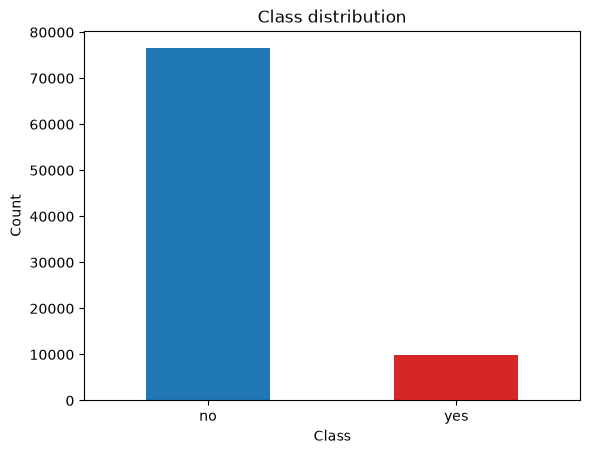

In [26]:
counts = y.value_counts()
positive_rate = (y == "yes").mean()

print(counts)
print(f"\nPositive class: {positive_rate:.1%} of the data, "f"about 1 in {round(1 / positive_rate)}")

counts.plot(kind="bar", title="Class distribution",color=["tab:blue", "tab:red"])
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

In [27]:
X.drop(['previous'], axis=1, inplace=True)

In [28]:
X.info()

<class 'pandas.DataFrame'>
Index: 86387 entries, 0 to 41187
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        86387 non-null  int64
 1   job        86387 non-null  str  
 2   marital    86387 non-null  str  
 3   education  86387 non-null  str  
 4   default    86387 non-null  str  
 5   housing    86387 non-null  str  
 6   loan       86387 non-null  str  
 7   contact    86387 non-null  str  
 8   month      86387 non-null  str  
 9   duration   86387 non-null  int64
 10  campaign   86387 non-null  int64
 11  pdays      86387 non-null  int64
 12  poutcome   86387 non-null  str  
dtypes: int64(4), str(9)
memory usage: 9.2 MB


In [29]:
num_cols = X.select_dtypes(include='number').columns
outlier_summary = []

for col in num_cols:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = X[(X[col] < lower) | (X[col] > upper)]
    outlier_pct = len(outliers) / len(X) * 100
    outlier_summary.append({
        'column': col,
        'outlier_count': len(outliers),
        'outlier_pct': round(outlier_pct, 2),
        'lower_bound': round(lower, 2),
        'upper_bound': round(upper, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values('outlier_pct', ascending=False)
outlier_df


,column,outlier_count,outlier_pct,lower_bound,upper_bound
1,duration,6208,7.19,-221.0,643.0
2,campaign,5470,6.33,-2.0,6.0
0,age,716,0.83,8.0,72.0
3,pdays,0,0.00,-1501.0,2499.0


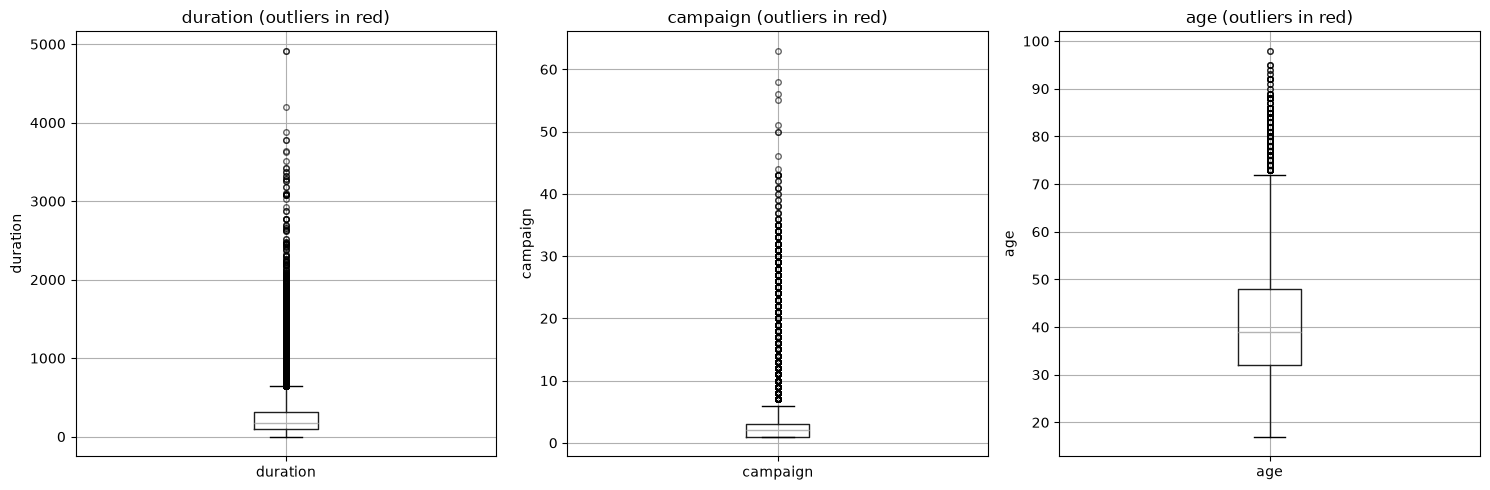

In [31]:
cols_with_outliers = ['duration', 'campaign', 'age']
n = len(cols_with_outliers)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes = axes.flatten()

for i, col in enumerate(cols_with_outliers):
    bp = X.boxplot(column=col, ax=axes[i], return_type='dict', 
                    flierprops=dict(marker='o', color='red', markersize=4, alpha=0.6))
    axes[i].set_title(f'{col} (outliers in red)')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()


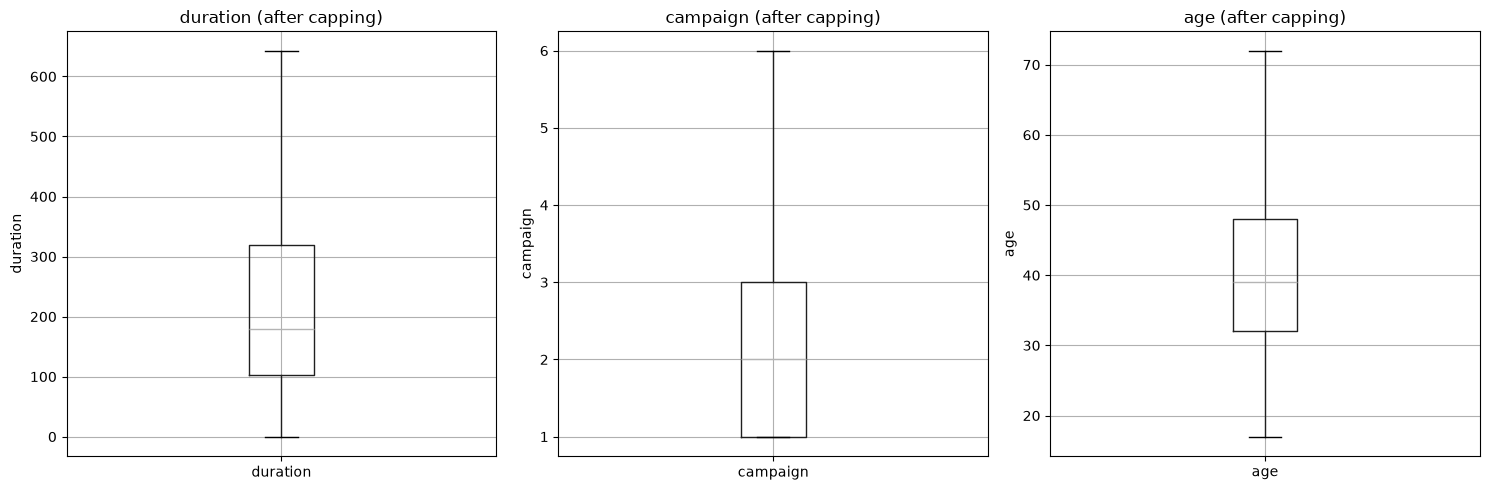

In [35]:
outlier_cols = ['duration', 'campaign', 'age']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes = axes.flatten()

for i, col in enumerate(outlier_cols):
    bp = X.boxplot(column=col, ax=axes[i], return_type='dict',
                    flierprops=dict(marker='o', color='red', markersize=4, alpha=0.6))
    axes[i].set_title(f'{col} (after capping)')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

In [36]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

In [37]:
from feature_engine.outliers import Winsorizer

In [38]:
capped = Winsorizer(
    capping_method="iqr",
    tail="both",
    fold=1.5,
    variables=["age", "duration", "campaign"]
)

In [39]:
capped.fit(X_train)

,capping_method,'iqr'
,tail,'both'
,fold,1.5
,variables,"['age', 'duration', ...]"
,add_indicators,False
,missing_values,'raise'
Name,Type,Value
feature_names_in_,list,"['age', 'job', 'marital', 'ed...on', ...]"
fold_,float,1.5
left_tail_caps_,dict,"{'age': 8.0, 'ca...gn': -2.0, 'du...on': -221.0}"
n_features_in_,int,13


In [40]:
X_train_capped = capped.transform(X_train)
X_test_capped = capped.transform(X_test)

In [41]:
numerical_cols = X_train.select_dtypes(include='number').columns
categorical_cols = X_train.select_dtypes(include=['object', 'category', 'string']).columns


In [42]:
Pro = ColumnTransformer(transformers=[('num', StandardScaler(),
                                        numerical_cols),('cat', OneHotEncoder(handle_unknown='ignore'),
                                                          categorical_cols)],remainder="drop")

In [43]:
X_train_processed = Pro.fit_transform(X_train_capped)
X_test_processed = Pro.transform(X_test_capped)


In [44]:
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (69109, 60)
Testing shape: (17278, 60)


In [45]:

MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "SVC":SVC(probability=True, random_state=42)
}

In [46]:

def scores(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]

    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(
            y, pred, pos_label='yes', zero_division=0
        ),
        "recall": recall_score(
            y, pred, pos_label='yes', zero_division=0
        ),
        "f1": f1_score(
            y, pred, pos_label='yes', zero_division=0
        ),
        "roc_auc": roc_auc_score(
            (y == 'yes').astype(int), proba
        )
    }


In [47]:
def run(strategy, sampler=None):
    """Train all 4 models with an optional sampler; return the fitted models and a results table."""
    fitted, rows = {}, []
    for name, model in MODELS.items():
        steps = [("scale", StandardScaler(with_mean=False))]
        if sampler is not None:
            steps.append(("balance", sampler))
        steps.append(("model", clone(model)))  
        pipe = Pipeline(steps).fit(X_train_processed, y_train)
        fitted[name] = pipe
        for split, (Xs, ys) in {"train": (X_train_processed, y_train), "test": (X_test_processed, y_test)}.items():
            rows.append({"strategy": strategy, "model": name, "split": split, **scores(pipe, Xs, ys)})
    return fitted, pd.DataFrame(rows)


In [48]:
baseline_models, baseline = run("No balancing")

baseline.pivot(
    index="model",
    columns="split",
    values=["accuracy", "precision", "recall", "f1"]
)

c:\Users\adeol\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


accuracy        precision        recall            f1  \
split                   test  train      test  train   test  train   test   
model                                                                       
Decision Tree          0.875  0.999     0.457  1.000  0.483  0.994  0.470   
KNN                    0.894  0.918     0.579  0.747  0.297  0.427  0.392   
Logistic Regression    0.899  0.901     0.612  0.629  0.336  0.348  0.434   
Random Forest          0.902  0.999     0.613  0.997  0.392  0.996  0.478   
SVC                    0.899  0.907     0.672  0.763  0.235  0.271  0.348   

                            
split                train  
model                       
Decision Tree        0.997  
KNN                  0.544  
Logistic Regression  0.448  
Random Forest        0.997  
SVC                  0.400

In [49]:
def diagnose(results, metric="f1", gap=0.15, low=0.6):
    table = results.pivot(index="model", columns="split", values=metric)
    table["gap"] = table["train"] - table["test"]

    def verdict(row):
        if row["gap"] > gap:
            return "Overfitting"
        if row["train"] < low:
            return "Underfitting"
        return "Good fit"

    table["diagnosis"] = table.apply(verdict, axis=1)
    return table


diagnose(baseline)

split,test,train,gap,diagnosis
model,,,,
Decision Tree,0.470,0.997,0.527,Overfitting
KNN,0.392,0.544,0.152,Overfitting
Logistic Regression,0.434,0.448,0.014,Underfitting
Random Forest,0.478,0.997,0.519,Overfitting
SVC,0.348,0.400,0.052,Underfitting


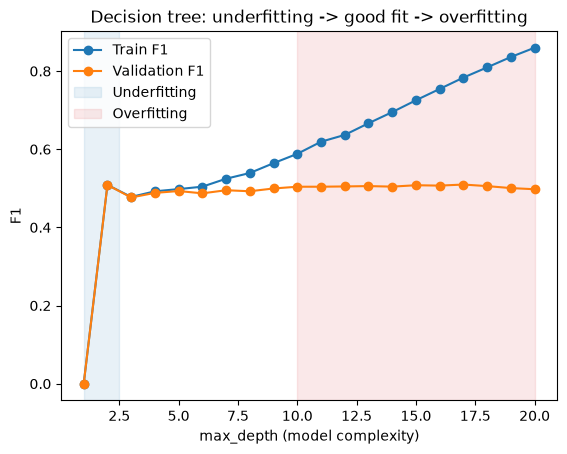

In [50]:
f1_yes = make_scorer(f1_score, pos_label="yes", zero_division=0)

depths = range(1, 21)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_f1, val_f1 = [], []

for d in depths:
    result = cross_validate(
        DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
        X_train_processed,
        y_train,
        cv=cv,
        scoring=f1_yes,
        return_train_score=True,
    )
    train_f1.append(result["train_score"].mean())
    val_f1.append(result["test_score"].mean())

plt.plot(depths, train_f1, marker="o", label="Train F1")
plt.plot(depths, val_f1, marker="o", label="Validation F1")
plt.axvspan(1, 2.5, alpha=0.1, color="tab:blue", label="Underfitting")
plt.axvspan(10, 20, alpha=0.1, color="tab:red", label="Overfitting")
plt.xlabel("max_depth (model complexity)")
plt.ylabel("F1")
plt.title("Decision tree: underfitting -> good fit -> overfitting")
plt.legend()
plt.show()

In [51]:
X_smote, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_processed, y_train)

print("Training data before SMOTE:", dict(y_train.value_counts()))
print("Training data after SMOTE: ", dict(pd.Series(y_smote).value_counts()))

Training data before SMOTE: {'no': np.int64(61167), 'yes': np.int64(7942)}
Training data after SMOTE:  {'no': np.int64(61167), 'yes': np.int64(61167)}


In [52]:
smote_models, smote = run("SMOTE", SMOTE(random_state=RANDOM_STATE))
smote.pivot(index="model", columns="split", values=["precision", "recall", "f1"])

c:\Users\adeol\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


precision        recall            f1       
split                    test  train   test  train   test  train
model                                                           
Decision Tree           0.425  1.000  0.540  0.994  0.475  0.997
KNN                     0.359  0.524  0.677  0.985  0.469  0.684
Logistic Regression     0.397  0.396  0.826  0.821  0.536  0.534
Random Forest           0.527  0.995  0.532  0.998  0.530  0.997
SVC                     0.419  0.458  0.820  0.897  0.555  0.606

In [74]:
X_under, y_under = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train_processed, y_train)

print("Training data before undersampling:", dict(y_train.value_counts()))
print("Training data after undersampling: ", dict(pd.Series(y_under).value_counts()))


Training data before undersampling: {'no': np.int64(61167), 'yes': np.int64(7942)}
Training data after undersampling:  {'no': np.int64(7942), 'yes': np.int64(7942)}


In [75]:
under_models, under = run("Undersampling", RandomUnderSampler(random_state=RANDOM_STATE))
under.pivot(index="model", columns="split", values=["precision", "recall", "f1"])

c:\Users\adeol\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


precision        recall            f1       
split                    test  train   test  train   test  train
model                                                           
Decision Tree           0.333  0.419  0.802  0.999  0.470  0.590
KNN                     0.314  0.348  0.752  0.840  0.443  0.493
Logistic Regression     0.388  0.387  0.837  0.832  0.531  0.528
Random Forest           0.395  0.460  0.884  1.000  0.546  0.630
SVC                     0.387  0.392  0.895  0.900  0.540  0.546

In [76]:
all_results = pd.concat([baseline, smote, under])
test_results = all_results[all_results["split"] == "test"]

comparison = test_results.pivot(index="model", columns="strategy", values=["precision", "recall", "f1"])
comparison = comparison.reindex(columns=["No balancing", "SMOTE", "Undersampling"], level=1)
comparison

precision                            recall         \
strategy            No balancing  SMOTE Undersampling No balancing  SMOTE   
model                                                                       
Decision Tree              0.444  0.432         0.333        0.470  0.538   
KNN                        0.571  0.361         0.314        0.293  0.681   
Logistic Regression        0.614  0.397         0.388        0.338  0.825   
Random Forest              0.610  0.538         0.395        0.389  0.539   
SVC                        0.679  0.419         0.387        0.234  0.825   

                                            f1                       
strategy            Undersampling No balancing  SMOTE Undersampling  
model                                                                
Decision Tree               0.802        0.457  0.479         0.470  
KNN                         0.752        0.387  0.472         0.443  
Logistic Regression         0.837        0.436  0.536         0.531  
Random Forest               0.884        0.475  0.538         0.546  
SVC                         0.895        0.348  0.556         0.540

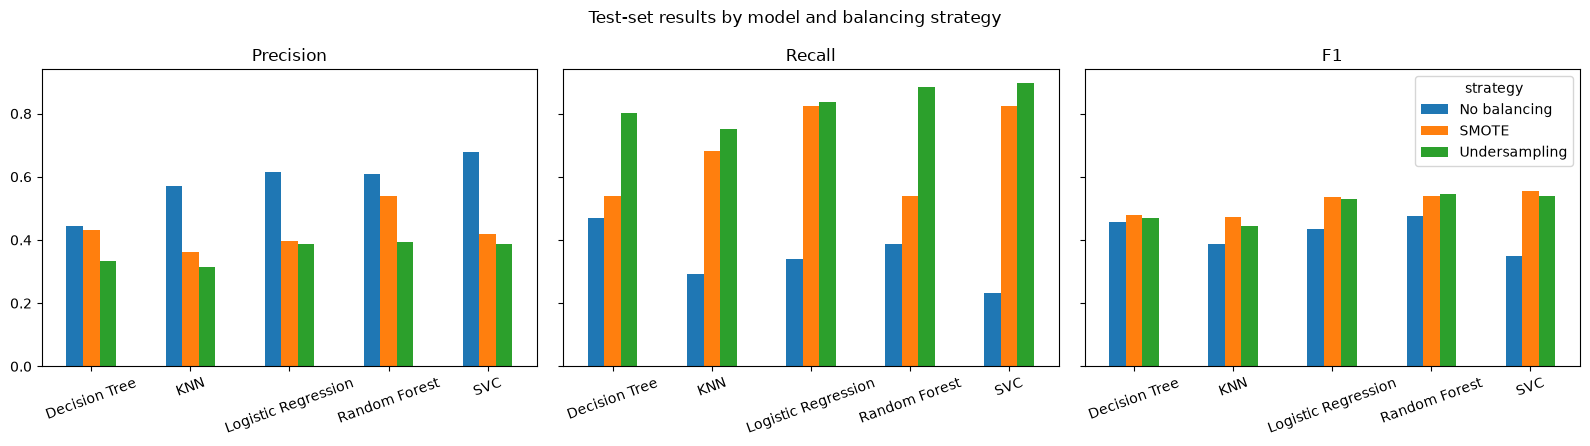

In [77]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    test_results.pivot(index="model", columns="strategy", values=metric)[
        ["No balancing", "SMOTE", "Undersampling"]
    ].plot(kind="bar", ax=ax, rot=20, legend=(metric == "f1"))
    ax.set_title(metric.capitalize())
    ax.set_xlabel("")
plt.suptitle("Test-set results by model and balancing strategy")
plt.tight_layout()
plt.show()

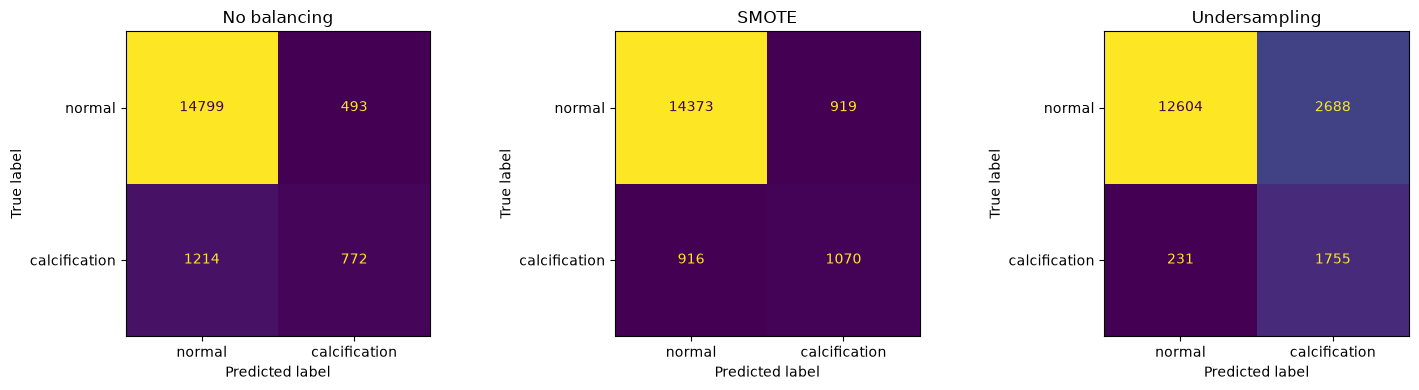

In [78]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (strategy, models) in zip(axes, {
    "No balancing": baseline_models, "SMOTE": smote_models, "Undersampling": under_models,
}.items()):
    ConfusionMatrixDisplay.from_estimator(
        models["Random Forest"], X_test_processed, y_test, ax=ax, colorbar=False,
        display_labels=["normal", "calcification"],
    )
    ax.set_title(strategy)
plt.tight_layout()
plt.show()

In [79]:
test_results.pivot_table(index=["strategy", "model"], values=["accuracy", "recall", "f1"])[
    ["accuracy", "recall", "f1"]
]


accuracy  recall     f1
strategy      model                                       
No balancing  Decision Tree           0.871   0.470  0.457
              KNN                     0.893   0.293  0.387
              Logistic Regression     0.899   0.338  0.436
              Random Forest           0.901   0.389  0.475
              SVC                     0.899   0.234  0.348
SMOTE         Decision Tree           0.865   0.538  0.479
              KNN                     0.825   0.681  0.472
              Logistic Regression     0.836   0.825  0.536
              Random Forest           0.894   0.539  0.538
              SVC                     0.849   0.825  0.556
Undersampling Decision Tree           0.792   0.802  0.470
              KNN                     0.783   0.752  0.443
              Logistic Regression     0.830   0.837  0.531
              Random Forest           0.831   0.884  0.546
              SVC                     0.825   0.895  0.540

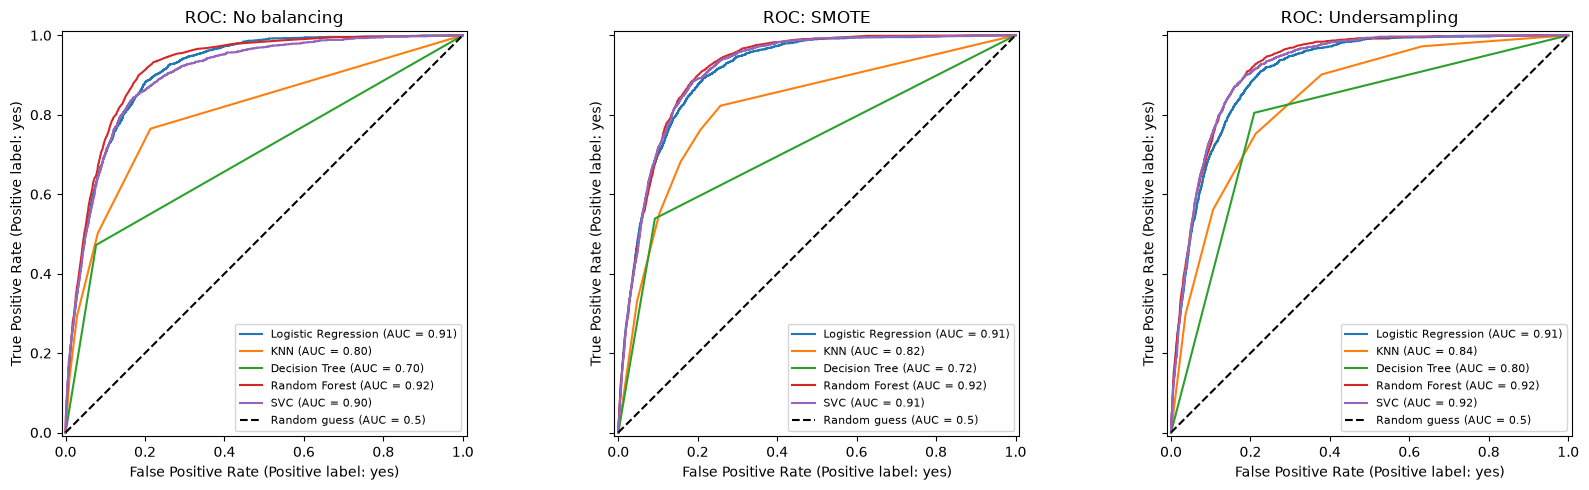

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, (strategy, models) in zip(axes, {
    "No balancing": baseline_models, "SMOTE": smote_models, "Undersampling": under_models,
}.items()):
    for name, model in models.items():
        RocCurveDisplay.from_estimator(model, X_test_processed, y_test, ax=ax, name=name)
    ax.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
    ax.set_title(f"ROC: {strategy}")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


In [81]:
auc_table = test_results.pivot(index="model", columns="strategy", values="roc_auc")[
    ["No balancing", "SMOTE", "Undersampling"]
]
auc_table

strategy,No balancing,SMOTE,Undersampling
model,,,
Decision Tree,0.698,0.723,0.798
KNN,0.803,0.818,0.843
Logistic Regression,0.909,0.909,0.910
Random Forest,0.918,0.916,0.922
SVC,0.901,0.913,0.920


In [88]:
proba = baseline_models["Random Forest"].predict_proba(X_test_processed)[:, 1]

y_test_num = (y_test == "yes").astype(int)

rows = []

for threshold in [0.5, 0.4, 0.3, 0.2, 0.1, 0.05]:
    pred = (proba >= threshold).astype(int)

    rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test_num, pred, zero_division=0),
        "recall": recall_score(y_test_num, pred, zero_division=0),
        "f1": f1_score(y_test_num, pred, zero_division=0),
        "flagged": int(pred.sum()),
    })

pd.DataFrame(rows)


,threshold,precision,recall,f1,flagged
0,0.50,0.607,0.396,0.479,1294
1,0.40,0.565,0.551,0.558,1937
2,0.30,0.513,0.679,0.585,2629
3,0.20,0.450,0.801,0.576,3534
4,0.10,0.374,0.911,0.530,4838
5,0.05,0.307,0.954,0.464,6176


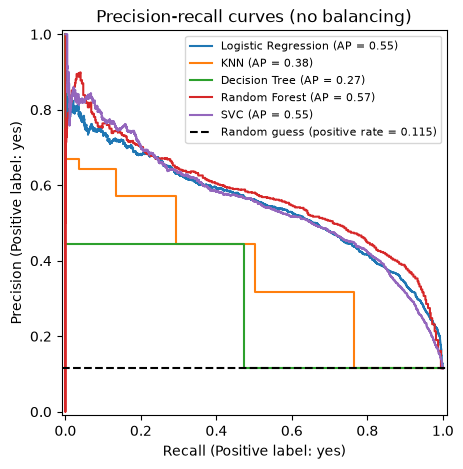

In [93]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, model in baseline_models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_test_processed,
        y_test,
        pos_label="yes",
        ax=ax,
        name=name
    )

positive_rate = (y_test == "yes").mean()
ax.axhline(
    positive_rate,
    color="k",
    linestyle="--",
    label=f"Random guess (positive rate = {positive_rate:.3f})"
)

ax.set_title("Precision-recall curves (no balancing)")
ax.legend(fontsize=8)
plt.show()